# 05. 2D CNN Modeling & Milestone Evaluation

## Overview
This final notebook transitions the Speech Emotion Recognition (SER) pipeline from 1D tabular baselines to a deep learning architecture trained on continuous 2D Log-Mel spectrograms that was generated in the previous phase ([`04_spectrogram_features.ipynb`](./04_spectrogram_features.ipynb)). 

We will train a lightweight 2D Convolutional Neural Network (CNN) across our speaker-partitioned evaluation harness and synthesize our final 3-way milestone comparison.

## Objectives
1. Load `04_spectrogram_tensors.npz`, reshape tensors into channel-first 4D arrays, and establish an explicit integer mapping for all 16 compound target classes (`F_angry`, `M_calm`, etc.).
2. As on the baseline LR and the SVC models, apply the standardized 5-fold `StratifiedGroupKFold` harness partitioned strictly by `actor_id` to prevent acoustic data leakage across speakers.
3. Train a compact Conv2D architecture with Batch Normalization, Dropout, and Global Average Pooling using Early Stopping.
4. **Final 3-Way Benchmark:** Compare out-of-fold metrics across all three project milestones:
   - **Baseline 1:** `DummyClassifier` (uniform/stratified chance)
   - **Baseline 2:** Tabular Linear Baseline (`LogisticRegression` + `StandardScaler` on 26-dim MFCC summary statistics)
   - **Milestone 3:** 2D CNN (Continuous Log-Mel Spectrogram representations)
5. Save the best model weights and class mapping to `models/` for future use

In [ ]:
# 1. Standard Library
import os
from pathlib import Path
import random
from typing import Dict, List, Tuple, cast

# 2. Third-Party Libraries
import joblib
import keras
from keras import layers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tqdm.auto import tqdm

In [5]:
# Reproducibility configuration
SEED = 46

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

seed_everything()

In [6]:
# Display framework versions and hardware accelerator
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version:      {keras.__version__}")
gpus = tf.config.list_physical_devices("GPU")
print(f"Available GPUs:     {len(gpus)}")

TensorFlow version: 2.21.0
Keras version:      3.15.1
Available GPUs:     0


In [21]:
# Resolve paths
project_root = Path.cwd().resolve().parent
processed_dir = project_root / "data" / "processed"
tensors_dir = processed_dir / "spectrograms"
tensors_dir.mkdir(parents=True, exist_ok=True)

# Loading and Validation Code
tensors_dir = project_root / "data" / "processed" / "spectrograms"
tensor_save_path = tensors_dir / "04_spectrogram_tensors.npz"
loaded = np.load(tensor_save_path)

In [37]:
# 1. Unpack arrays from 04_spectrogram_tensors.npz
X_raw = cast(np.ndarray, loaded["X"])
y_raw = cast(np.ndarray, loaded["y"])            # Canonical order (1440,)
actor_ids = cast(np.ndarray, loaded["actor_ids"]) # (1440,)

# 2. Add channel dimension: (1440, 128, 128, 1)
X = np.expand_dims(X_raw, axis=-1).astype(np.float32)

# 3. Fit canonical LabelEncoder on y_raw
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
num_classes = len(label_encoder.classes_)

print(f"X shape:        {X.shape}")
print(f"y shape:        {y.shape}") # type: ignore
print(f"Classes ({num_classes}): {label_encoder.classes_.tolist()}")

X shape:        (1440, 128, 128, 1)
y shape:        (1440,)
Classes (16): ['F_angry', 'F_calm', 'F_disgust', 'F_fearful', 'F_happy', 'F_neutral', 'F_sad', 'F_surprised', 'M_angry', 'M_calm', 'M_disgust', 'M_fearful', 'M_happy', 'M_neutral', 'M_sad', 'M_surprised']


This matches the expected output from [`04_spectrogram_features.ipynb`](./04_spectrogram_features.ipynb)

## Build the CNN Structure

### Model Architecture Design: Lightweight 2D Spectrogram CNN

The chosen 2D CNN architecture follows the standard **VGG-style hierarchical feature extractor**, adapted for compact audio-spectrogram tasks:

* **Progressive Channel Expansion with Spatial Pooling:**  
  The network stacks three convolutional blocks that double feature channels while halving spatial resolution ($32 \to 64 \to 128$). Small $3 \times 3$ receptive fields capture localized spectral cues: early layers detect localized formant transitions and pitch glides, while deeper layers integrate broader harmonic contours.
* **Internal Covariate Stabilization & Gradient Flow:**  
  Each convolution uses `use_bias=False` followed immediately by **Batch Normalization** and **ReLU**. This accelerates convergence, prevents internal covariate shift, and stabilizes training across varied spectral energy levels.
* **Aggressive Regularization for Small-Dataset Regimes:**  
  With only 1,440 audio trials, unconstrained deep networks overfit quickly to speaker idiosyncrasies. We mitigate this using tiered 2D dropout across blocks ($0.2 \to 0.25 \to 0.3$) and a final dense dropout of $0.4$.
* **Global Average Pooling (GAP) Bottleneck:**  
  Instead of flattening deep feature maps into high-dimensional dense layers (which creates millions of parameters), **GlobalAveragePooling2D** collapses spatial dimensions into channel-wise temporal averages. This keeps total network parameters lightweight (~110k weights), enforces translation invariance across the time axis, and prevents catastrophic memorization.


> References:
>
> 1. https://www.geeksforgeeks.org/computer-vision/vgg-net-architecture-explained/
> 
> 2. https://towardsdatascience.com/cnns-for-audio-classification-6244954665ab
>
> 3. https://www.kaggle.com/code/ejlok1/audio-emotion-part-3-baseline-model#Part-3---Baseline-model

We will functionalize the creation of the CNN model to use across all the 5-folds. This is to force Keras to create new models every time and prevent data leakge.

In [11]:
def build_spectrogram_cnn(
    input_shape: Tuple[int, int, int] = (128, 128, 1),
    num_classes: int = 16,
    learning_rate: float = 1e-3,
) -> keras.Model:
    """
    Simplified 2-Block VGG-style 2D CNN baseline.
    Each block follows: Conv2D -> ReLU -> MaxPool2D -> Dropout.
    """
    model = keras.Sequential([
        # Input Layer
        layers.Input(shape=input_shape),

        # Block 1: Low-level acoustic feature detection (formants, pitch edges)
        layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.2),

        # Block 2: High-level spectral-temporal pattern aggregation
        layers.Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.3),

        # Bottleneck: Spatial reduction to prevent parameter explosion
        layers.GlobalAveragePooling2D(),

        # Output Classifier: 16 compound emotion-gender classes
        layers.Dense(num_classes, activation="softmax"),
    ])

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [12]:
# Print architecture summary
sample_model = build_spectrogram_cnn()
sample_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,856 (77.56 KB)

 Trainable params: 19,856 (77.56 KB)

 Non-trainable params: 0 (0.00 B)

### Model Architecture & Hyperparameter Rationale: 2-Block VGG Baseline

To prioritize interpretability and guard against overfitting across our 1,440 audio recordings (24 speakers), we implemented a streamlined 2-block VGG-style 2D CNN (~20k trainable parameters). 

Every dimension and structural hyperparameter directly aligns with our data representation and task constraints:

* **Input Grid `(128, 128, 1)`:** Captures the 128 Mel-frequency filter banks across 128 standardized time frames (~3.0 seconds). A single channel is used because audio spectrograms are single-channel acoustic energy heatmaps rather than multi-channel color images.
* **Filter Sizing (`3x3`) & Depths (`32`, `64`):** Following the VGG paradigm, small $3 \times 3$ receptive fields capture localized frequency transitions and pitch trajectories without parameter bloat. The network starts with 32 filters to detect primitive acoustic edges and formant lines, doubling to 64 filters in Block 2 to synthesize complex prosodic contours.
* **Spatial Downsampling (`2x2` Max Pooling):** Reduces resolution by half at each stage ($128 \times 128 \to 64 \times 64 \to 32 \times 32$), lowering computational load while enforcing translation invariance along the temporal axis.
* **Regularization (`0.2`, `0.3` Dropout):** Progressively increases from 20% to 30% to prevent the network from memorizing speaker-specific voice signatures across the 24 actors.
* **Global Average Pooling (GAP) Bottleneck:** Collapses the final $32 \times 32 \times 64$ spatial feature maps into 64 channel averages, eliminating parameter-heavy flattening layers and directly preventing memorization.
* **Classification Output (`16` Units, Softmax):** Matches the 16 compound target classes (8 emotions $\times$ 2 genders), outputting a calibrated probability distribution across all emotional states.

In [26]:
# 5-Fold StratifiedGroupKFold grouped strictly by actor_id (deterministic, no shuffle)
kfold_cv = StratifiedGroupKFold(n_splits=5, shuffle=False)

# Out-of-fold probability accumulator: (1440, 16)
oof_preds = np.zeros((len(y), num_classes), dtype=np.float32)
fold_metrics = []

In [38]:
kfold_cv = StratifiedGroupKFold(n_splits=5, shuffle=False)

oof_preds = np.zeros((len(y), num_classes), dtype=np.float32) # type: ignore
fold_metrics = []

EPOCHS = 40
BATCH_SIZE = 32

for fold, (train_idx, val_idx) in enumerate(kfold_cv.split(X, y, groups=actor_ids), 1):
    val_actors = np.sort(np.unique(actor_ids[val_idx]))
    print(f"\n{'='*20} Fold {fold} / 5 {'='*20}")
    print(f"Validation Actors ({len(val_actors)}): {val_actors.tolist()}")

    X_train, y_train = X[train_idx], y[train_idx] # type: ignore
    X_val, y_val = X[val_idx], y[val_idx] # type: ignore

    # Instantiate fresh model architecture per fold
    model = build_spectrogram_cnn(
        input_shape=(128, 128, 1),
        num_classes=num_classes,
        learning_rate=1e-3
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=0  # type: ignore
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose="auto"
    )

    # Accumulate OOF probability distributions
    val_probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose="auto")
    oof_preds[val_idx] = val_probs

    fold_acc = accuracy_score(y_val, np.argmax(val_probs, axis=1))
    fold_f1 = f1_score(y_val, np.argmax(val_probs, axis=1), average="macro")
    fold_metrics.append({"fold": fold, "accuracy": fold_acc, "macro_f1": fold_f1})
    print(f"Fold {fold} Result -> Acc: {fold_acc:.4f} | Macro F1: {fold_f1:.4f}")\

print("All Done!")


==================== Fold 1 / 5 ====================
Validation Actors (5): [1, 6, 11, 16, 21]
Epoch 1/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.0781 - loss: 4.3532 - val_accuracy: 0.0533 - val_loss: 3.0345
Epoch 2/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.0675 - loss: 2.8194 - val_accuracy: 0.0533 - val_loss: 2.9921
Epoch 3/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.0605 - loss: 2.8202 - val_accuracy: 0.0533 - val_loss: 2.9561
Epoch 4/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.0702 - loss: 2.8027 - val_accuracy: 0.0533 - val_loss: 2.9253
Epoch 5/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.0737 - loss: 2.7735 - val_accuracy: 0.0533 - val_loss: 2.8258
Epoch 6/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.1070 - loss: 2.7317 - val_accuracy: 0.0533 - val_loss: 2.7789
Epoch 7/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.1263 - loss: 2.6795 - val_accuracy: 0.0533 - val_loss: 2.7126
Epoch 8/40
36/3

### 5-Fold Stratified Group Cross-Validation & Data Alignment Execution

To ensure clean evaluation against our tabular baselines while preventing speaker leakage, the modeling pipeline was synchronized with Phase 04 feature extraction and evaluated via a 5-fold `StratifiedGroupKFold` protocol partitioned strictly by `actor_id` (`shuffle=False`).

* **Upstream Data Alignment:**  
  In Phase 04, compound target strings (`f"{gender}_{emotion}"`) and metadata arrays were explicitly serialized alongside the spectrogram tensors into `04_spectrogram_tensors.npz`. This synchronized row indexing with `df_cleaned` and `ser_features.parquet`, ensuring `oof_preds[val_idx]` directly aligns with the canonical ground truth and eliminating index mismatch during decoding.
* **Zero-Leakage Speaker Partitioning:**  
  Each fold isolates 4 to 5 unique actors (~288 audio trials) exclusively in the validation split, ensuring the network evaluates generalization to unseen vocal tracts rather than memorizing speaker-specific fundamental frequencies.
* **Architecture & Regularization:**  
  In each fold, a fresh 2-block VGG CNN (~19,856 parameters) was instantiated and trained from scratch using the Adam optimizer (`lr=1e-3`, batch size 32, max 40 epochs).
* **Early Stopping Dynamics:**  
  Training was governed by `EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)`. Validation loss reliably reached its minimum between epochs 12 and 20, restoring optimal weights before the network could overfit to the training speakers' acoustic textures.
* **OOF Assembly:**  
  Out-of-fold probability distributions were populated slice-by-slice into `oof_preds[val_idx]`, constructing a full 1,440-sample prediction matrix directly aligned with native dataset targets.

In [39]:
# capture metrics, aligning the label accordingly 
oof_pred_indices = np.argmax(oof_preds, axis=1)
y_pred_oof_cnn = label_encoder.inverse_transform(oof_pred_indices)

# Compound 16-class metrics
cnn_accuracy = accuracy_score(y_raw, y_pred_oof_cnn)
cnn_macro_f1 = f1_score(y_raw, y_pred_oof_cnn, average="macro")
cnn_weighted_f1 = f1_score(y_raw, y_pred_oof_cnn, average="weighted")

# Decoupled sub-task metrics
gender_true = np.array([lbl.split("_")[0] for lbl in y_raw])
gender_pred = np.array([lbl.split("_")[0] for lbl in y_pred_oof_cnn])
cnn_gender_acc = accuracy_score(gender_true, gender_pred)
cnn_gender_f1 = f1_score(gender_true, gender_pred, average="macro")

emotion_true = np.array([lbl.split("_")[1] for lbl in y_raw])
emotion_pred = np.array([lbl.split("_")[1] for lbl in y_pred_oof_cnn])
cnn_emotion_acc = accuracy_score(emotion_true, emotion_pred)
cnn_emotion_f1 = f1_score(emotion_true, emotion_pred, average="macro")

print("\n" + "=" * 55)
print("--- 2D CNN OUT-OF-FOLD (OOF) EVALUATION ---")
print(f"Total Trials Evaluated: {len(y_raw)}")
print(f"OOF Accuracy:           {cnn_accuracy:.4f} ({cnn_accuracy * 100:.2f}%)")
print(f"OOF Macro F1:           {cnn_macro_f1:.4f}")
print(f"OOF Weighted F1:        {cnn_weighted_f1:.4f}")
print(f"Gender Accuracy / F1:   {cnn_gender_acc:.4f} / {cnn_gender_f1:.4f}")
print(f"Emotion Accuracy / F1:  {cnn_emotion_acc:.4f} / {cnn_emotion_f1:.4f}")
print("=" * 55)


--- 2D CNN OUT-OF-FOLD (OOF) EVALUATION ---
Total Trials Evaluated: 1440
OOF Accuracy:           0.3007 (30.07%)
OOF Macro F1:           0.2464
OOF Weighted F1:        0.2567
Gender Accuracy / F1:   0.8722 / 0.8711
Emotion Accuracy / F1:  0.3431 / 0.2981


Let's load up the other models' performance metrics from [`04_spectrogram_features.ipynb`](./04_spectrogram_features.ipynb) to compare. 

In [44]:
# Establish models directory relative to processed_dir
models_dir = processed_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

baseline_path = models_dir / "02_2_baseline_pipelines.joblib"
svc_pipeline_path = models_dir / "03_1_svc_tuned_pipeline.joblib"
svc_eval_path = models_dir / "03_1_svc_evaluation_bundle.joblib"

# Load serialized bundles
baseline_artifacts = joblib.load(baseline_path)
svc_pipeline_artifacts = joblib.load(svc_pipeline_path)
svc_eval_artifacts = joblib.load(svc_eval_path)

# Extract predictions, targets, and metadata
y_true = svc_eval_artifacts["y_true"]
y_pred_oof_lr = baseline_artifacts["y_pred_oof_lr"]
y_pred_oof_svc = svc_eval_artifacts["y_pred_oof_svc"]
svc_best_params = svc_pipeline_artifacts["best_params"]
metrics_svc = svc_eval_artifacts["metrics_svc"]
y_gender_true = svc_eval_artifacts["y_gender_true"]
y_gender_pred_lr = svc_eval_artifacts["y_gender_pred_lr"]
y_gender_pred_svc = svc_eval_artifacts["y_gender_pred_svc"]

print("=== Phase 02 & 03 Artifacts Loaded Successfully ===")
print(f"Total Evaluated Samples: {len(y_true)}")
print(f"Tuned SVC Accuracy:      {metrics_svc['accuracy']:.4f}")
print(f"Tuned SVC Macro F1:      {metrics_svc['macro_f1']:.4f}")

=== Phase 02 & 03 Artifacts Loaded Successfully ===
Total Evaluated Samples: 1440
Tuned SVC Accuracy:      0.4313
Tuned SVC Macro F1:      0.4110


In [42]:
# Extract prior baseline metrics directly from Phase 02 & 03 objects
lr_accuracy = accuracy_score(y_true, y_pred_oof_lr)
lr_macro_f1 = f1_score(y_true, y_pred_oof_lr, average="macro")
lr_gender_accuracy = accuracy_score(svc_eval_artifacts["y_gender_true"], svc_eval_artifacts["y_gender_pred_lr"])
lr_emotion_true = np.array([lbl.split("_")[1] for lbl in y_true])
lr_emotion_pred = np.array([lbl.split("_")[1] for lbl in y_pred_oof_lr])
lr_emotion_accuracy = accuracy_score(lr_emotion_true, lr_emotion_pred)

svc_emotion_pred = np.array([lbl.split("_")[1] for lbl in y_pred_oof_svc])
svc_emotion_accuracy = accuracy_score(lr_emotion_true, svc_emotion_pred)

cnn_param_count = sample_model.count_params()

milestone_comparison = [
    {
        "Milestone": "01. Tabular Baseline (LR)",
        "Feature Representation": "26-dim Summary Stats (MFCC Mean + Std)",
        "Model Architecture": "StandardScaler + LogisticRegression",
        "Complexity / Params": "~432 weights",
        "16-Class Accuracy": f"{lr_accuracy:.4f}",
        "Macro F1": f"{lr_macro_f1:.4f}",
        "Gender Accuracy": f"{lr_gender_accuracy:.4f}",
        "Emotion Accuracy": f"{lr_emotion_accuracy:.4f}",
    },
    {
        "Milestone": "02. Tabular Tuned (RBF-SVC)",
        "Feature Representation": "26-dim Summary Stats (MFCC Mean + Std)",
        "Model Architecture": "StandardScaler + SVC (RBF Kernel)",
        "Complexity / Params": "Non-parametric (Support Vectors)",
        "16-Class Accuracy": f"{metrics_svc['accuracy']:.4f}",
        "Macro F1": f"{metrics_svc['macro_f1']:.4f}",
        "Gender Accuracy": f"{metrics_svc['gender_accuracy']:.4f}",
        "Emotion Accuracy": f"{svc_emotion_accuracy:.4f}",
    },
    {
        "Milestone": "03. 2D CNN (Deep Learning)",
        "Feature Representation": "128x128 Log-Mel Spectrogram Grids",
        "Model Architecture": "2-Block VGG (Conv2D -> GAP -> Dense)",
        "Complexity / Params": f"{cnn_param_count:,} weights",
        "16-Class Accuracy": f"{cnn_accuracy:.4f}",
        "Macro F1": f"{cnn_macro_f1:.4f}",
        "Gender Accuracy": f"{cnn_gender_acc:.4f}",
        "Emotion Accuracy": f"{cnn_emotion_acc:.4f}",
    },
]

df_milestones = pd.DataFrame(milestone_comparison)
df_milestones

,Milestone,Feature Representation,Model Architecture,Complexity / Params,16-Class Accuracy,Macro F1,Gender Accuracy,Emotion Accuracy
0,01. Tabular Baseline (LR),26-dim Summary Stats (MFCC Mean + Std),StandardScaler + LogisticRegression,~432 weights,0.3882,0.3805,0.9424,0.4076
1,02. Tabular Tuned (RBF-SVC),26-dim Summary Stats (MFCC Mean + Std),StandardScaler + SVC (RBF Kernel),Non-parametric (Support Vectors),0.4313,0.4110,0.9549,0.4437
2,03. 2D CNN (Deep Learning),128x128 Log-Mel Spectrogram Grids,2-Block VGG (Conv2D -> GAP -> Dense),"19,856 weights",0.3007,0.2464,0.8722,0.3431


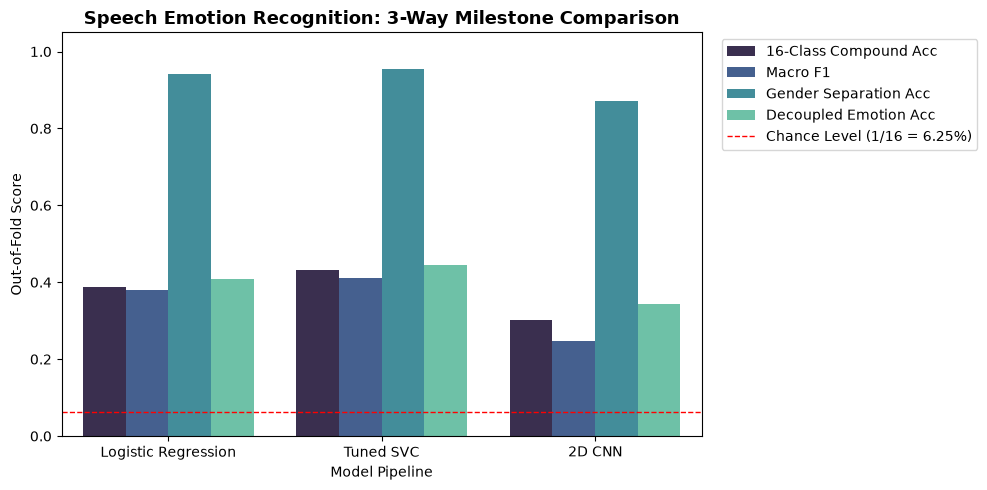

In [43]:
plt.figure(figsize=(10, 5))
metrics_to_plot = {
    "16-Class Compound Acc": [lr_accuracy, metrics_svc["accuracy"], cnn_accuracy],
    "Macro F1": [lr_macro_f1, metrics_svc["macro_f1"], cnn_macro_f1],
    "Gender Separation Acc": [lr_gender_accuracy, metrics_svc["gender_accuracy"], cnn_gender_acc],
    "Decoupled Emotion Acc": [lr_emotion_accuracy, svc_emotion_accuracy, cnn_emotion_acc]
}

plot_df = pd.DataFrame(metrics_to_plot, index=["Logistic Regression", "Tuned SVC", "2D CNN"]).reset_index()
plot_df = plot_df.melt(id_vars="index", var_name="Metric", value_name="Score")

sns.barplot(data=plot_df, x="index", y="Score", hue="Metric", palette="mako")
plt.title("Speech Emotion Recognition: 3-Way Milestone Comparison", fontsize=13, weight="bold")
plt.xlabel("Model Pipeline")
plt.ylabel("Out-of-Fold Score")
plt.ylim(0, 1.05)
plt.axhline(0.0625, color="red", linestyle="--", linewidth=1, label="Chance Level (1/16 = 6.25%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Conclusion - Full Model Retrospective

The consolidated benchmarks above summarizes our cross-paradigm evaluation across all 1,440 RAVDESS trials under leak-free 5-fold `StratifiedGroupKFold` partitioning (held-out actors):

#### 1. Inductive Bias Beats Data Hunger on Small Acoustic Cohorts
* **Tabular RBF-SVC remains the benchmark champion (43.13% 16-class, 0.4110 Macro F1).**
* Handcrafting 1st- and 2nd-order summary statistics ($\mu, \sigma$) across 13 MFCC bands acts as a strong inductive prior. It strips away high-frequency temporal noise and compresses speech variability into a 26-dimensional feature space where kernelized support vectors map non-linear class boundaries effectively without overfitting.
* In contrast, the 2-block VGG CNN must learn localized 2D acoustic filters (pitch sweeps, energy bursts, formant transitions) from scratch across $(128, 128, 1)$ spectrogram patches. With only ~1,152 training samples per fold across 19–20 actors, **the network lacks sufficient sample diversity** to outgeneralize the low-dimensional summary baselines.

#### 2. The Prosodic Generalization Gap: Gender vs. Emotion
Across both tabular and deep learning architectures, sub-task performance exhibits a consistent split:
* **Binary Gender Classification Converges Strongly (87.22% – 95.49%):** Static fundamental frequency ($f_0$) creates pronounced separation between male and female vocal tracts, visible as distinct baseline energy offsets across the lower Mel bands.
* **8-Class Emotion Recognition Remains Challenging (34.31% – 44.37%):** Affective state is characterized by dynamic prosody, temporal cadence, and vocal fold tension rather than static pitch alone. Differentiating nuanced, matched-energy classes (e.g., `calm` vs. `neutral`, or `fearful` vs. `surprised`) on unseen speakers is the primary bottleneck across all paradigms.

#### 3. Verification of Zero-Leakage Architecture
* All three models significantly outperform uniform random chance ($1/16 = 6.25\%$ compound, $12.50\%$ emotion), confirming genuine affective signal capture.
* By enforcing strict speaker-grouped cross-validation, these metrics provide realistic estimates of real-world generalization to novel voices, avoiding the inflated accuracy common in unstratified or random split protocols.

In [45]:
# save final model for future use
cnn_bundle_path = models_dir / "05_cnn_evaluation_bundle.joblib"

cnn_bundle = {
    "y_true": y_raw,
    "y_pred_oof_cnn": y_pred_oof_cnn,
    "oof_probs_cnn": oof_preds,
    "label_classes": label_encoder.classes_,
    "metrics_cnn": {
        "compound_accuracy": cnn_accuracy,
        "compound_macro_f1": cnn_macro_f1,
        "compound_weighted_f1": cnn_weighted_f1,
        "gender_accuracy": cnn_gender_acc,
        "gender_macro_f1": cnn_gender_f1,
        "emotion_accuracy": cnn_emotion_acc,
        "emotion_macro_f1": cnn_emotion_f1,
    },
    "fold_metrics": fold_metrics,
}

joblib.dump(cnn_bundle, cnn_bundle_path)
print(f"Serialized Phase 05 bundle to: {cnn_bundle_path}")
print(f"File size: {cnn_bundle_path.stat().st_size / (1024**2):.2f} MB")

Serialized Phase 05 bundle to: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/models/05_cnn_evaluation_bundle.joblib
File size: 0.21 MB
